# 2D Expansion

Here we use the Gutzwiller Ansatz to model 2D exapnsion

We will take ${\cal H}={\cal T}+{\cal V}+{\cal U}$ with
\begin{align}
{\cal T} &= \sum_{ij} -g_{ij} a_i^\dagger a_j\\
{\cal V}&=\sum_i V_i a_i^\dagger a_i\\
{\cal U}&=\frac{U}{2}\sum_j a_j^\dagger a_j^\dagger a_j a_j
\end{align}
and for now we will just hard-code nearest-neighbor 2D $g_{ij}=g$ for nearest neighbors, but otherwise zero.  The $V$ term will be used for the initial trapping.  We will first confine the system to a circular box trap.  We will then minimize the energy using imaginary time evolution. We will then turn off the trap and do expansion.

We make the ansatz
\begin{align}
|\psi\rangle = \prod_j \sum_n f_{jn} |n\rangle_j
\end{align}
so $f_{jn}$ is the amplitude for having $n$ particles on site $j$.  

We will store it as an `OffsetArray`.  The first two indices will be the site number (from 1 to Lx, and 1 to Ly) and the third index the occupation number

We will always have the boundary cells be fixed -- and use them as "ghost" cells.

In [1]:
import Pkg
Pkg.add(["Makie","GLMakie","MakieCore","Observables",
        "OffsetArrays","LaTeXStrings"
        ])

   Resolving package versions...
   Installed FFMPEG_jll ─ v9.0.2+0
  Installing 1 artifacts
   Installed artifact FFMPEG                  12.2 MiB
    Updating `~/.julia/environments/v1.12/Project.toml`
  [e9467ef8] + GLMakie v0.13.15
  [b964fa9f] + LaTeXStrings v1.4.1
  [ee78f7c6] + Makie v0.24.15
  [20f20a25] + MakieCore v0.10.0
  [510215fc] + Observables v0.5.5
  [6fe1bfb0] + OffsetArrays v1.17.0
    Updating `~/.julia/environments/v1.12/Manifest.toml`
  [621f4979] + AbstractFFTs v1.5.0
  [1520ce14] + AbstractTrees v0.4.5
  [7d9f7c33] + Accessors v0.1.45
  [79e6a3ab] + Adapt v4.7.1
  [35492f91] + AdaptivePredicates v1.2.0
  [66dad0bd] + AliasTables v1.1.3
  [27a7e980] + Animations v0.4.2
  [67c07d97] + Automa v1.2.0
  [13072b0f] + AxisAlgorithms v1.1.0
  [39de3d68] + AxisArrays v0.4.8
  [18cc8868] + BaseDirs v1.4.0
  [fa961155] + CEnum v0.5.0
  [96374032] + CRlibm v1.0.2
  [d360d2e6] + ChainRulesCore v1.26.1
  [6b39b394] + CodecZstd v0.8.7
  [a2cac450] + ColorBrewer v0.4.2
  [35d6a

In [1]:
import Pkg
Pkg.activate("makie-env")
Pkg.add(["Makie","GLMakie","MakieCore","Observables",
        "OffsetArrays","LaTeXStrings"
        ])
Pkg.precompile()
Pkg.instantiate()
Base.active_project()
Base.current_project()
VERSION

  Activating project at `~/Documents/MacbookPro/Gutzwiller/makie-env`
     Project No packages added to or removed from `~/Documents/MacbookPro/Gutzwiller/makie-env/Project.toml`
    Manifest No packages added to or removed from `~/Documents/MacbookPro/Gutzwiller/makie-env/Manifest.toml`
Precompiling packages...
  81621.9 ms  ✓ Makie
   5731.7 ms  ✓ IntervalArithmetic → IntervalArithmeticMakieExt
  29299.2 ms  ✓ WGLMakie
  32384.2 ms  ✓ CairoMakie
  53027.0 ms  ✓ GLMakie
  5 dependencies successfully precompiled in 141 seconds. 330 already precompiled.
  31 dependencies precompiled but different versions are currently loaded (ArgTools, Base64, Dates, Downloads, InteractiveUtils, JLLWrappers, JuliaSyntaxHighlighting, LibCURL, LibCURL_jll, LibGit2, LibGit2_jll, LibSSH2_jll, Logging, Markdown, MozillaCACerts_jll, NetworkOptions, OpenSSL_jll, Pkg, Pkg → REPLExt, PrecompileTools, Preferences, Printf, REPL, StyledStrings, TOML, Tar, UUIDs, Unicode, Zlib_jll, nghttp2_jll and p7zip_jll). Resta

v"1.12.7"

In [2]:
using OffsetArrays
using LaTeXStrings
using LinearAlgebra
using Random
using GLMakie, Makie.Colors
using Observables

[ Info: Precompiling GLMakie [e9467ef8-e4e7-5192-8a1a-b1aee30e663a](cache misses: wrong dep version loaded (6))
[ Info: Precompiling GLMakie [e9467ef8-e4e7-5192-8a1a-b1aee30e663a] (cache misses: wrong dep version loaded (12))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up


In [2]:
"""
    Gutz()

Abstract type for Gutzwiler wavefunction.  I hard coded it as a subtype of an AbstractArray, 
so that I can make use of some of the broadcasting aparatus.  In future version should probably
leave that generic, and hook into the broadcasting by hand.
"""
abstract type Gutz <:AbstractArray{ComplexF64,3} end

"""
    Gutz2D(Lx,Ly,maxN)

Represents a Gutzwiller wavefunction.  `Lx`,`Ly` are the spatial size, while `maxN` is the maximum number of particles on a site.

Contains a single field: `data` which stores the `f's` as an OffsetArray
"""
mutable struct Gutz2D <:Gutz
    data :: OffsetArray{ComplexF64, 3, Array{ComplexF64, 3}}
end

Gutz2D(Lx,Ly,maxN)=Gutz2D(OffsetArray(zeros(ComplexF64,2Lx+1,2Ly+1,maxN+1),(-Lx-1,-Ly-1,-1)))

"""
    Lx(f::Gutz2D)

Extracts the largest x-value
"""
Lx(f::Gutz2D)=axes(f.data,1)[end]

"""
    Lxmin(f::Gutz2D)

Extracts the smallest x-value
"""
Lxmin(f::Gutz2D)=axes(f.data,1)[begin]

"""
    Ly(f::Gutz2D)

Extracts the largest y-value
"""
Ly(f::Gutz2D)=axes(f.data,2)[end]

"""
    Lymin(f::Gutz2D)

Extracts the smallest y-value
"""
Lymin(f::Gutz2D)=axes(f.data,2)[begin]

"""
    maxN(f::Gutz2D)

Extracts the largest on-site N
"""
maxN(f::Gutz2D)=axes(f.data,3)[end]

"""
    minN(f::Gutz2D)

Extracts the smallest on-site N
"""
minN(f::Gutz2D)=axes(f.data,3)[begin]

"""
    sites(f::Gutz2D)
    xv(f::Gutz2D)

Gives the site indices
"""
sites(f::Gutz2D)=CartesianIndices(axes(f.data)[1:2])
xv(f::Gutz2D)=sites(f)

"""
    size(f::Gutz2D)

Gives the size of the underlying data
"""
Base.size(f::Gutz2D)=size(f.data)

@doc raw"""
    nv(f)

gives the values of the $n$ coordinates in $f(j, n)$
"""
nv(f::Gutz2D)=axes(f.data,3)
rightnv(f)=Iterators.drop(nv(f),1)


function Base.show(io::IO,f::Gutz2D)
    print(io,"G2D(x=$(Lxmin(f)):$(Lx(f)),y=$(Lymin(f)):$(Ly(f));maxN=$(maxN(f)))")
end

function Base.show(io::IO,::MIME"text/plain",f::Gutz2D)
    print(io,"G2D(x=$(Lxmin(f)):$(Lx(f)),y=$(Lymin(f)):$(Ly(f));maxN=$(maxN(f)))")
end

#pass-through functions for manipulating data
Base.getindex(f::Gutz,inds...)=f.data[inds...]
Base.setindex!(f::Gutz, args...)=setindex!(f.data,args...)

#slicing
sitewf(f::Gutz,siteinds::Int...)= f.data[siteinds...,:]
nslice(f::Gutz2D,n::Int)=f.data[:,:,n]

function psi(f::Gutz)
    nvals = rightnv(f) 
    xvals = xv(f) 
    result=[sum(sqrt(n)*f[j,n]*conj(f[j,n-1]) for n in nvals) for j in xvals]
end

@doc raw"""
    psi!(target,f)
Calculates the order parameter $\psi_j=\sum_n \sqrt{n} f_{j,n-1}^* f_{jn}$, and places
it in `target`.  
"""
function psi!(target,f)
    nvals = rightnv(f) 
    xvals=xv(f) 
    for j in xvals
        target[j]=sum(sqrt(n)*f[j,n]*conj(f[j,n-1]) for n in nvals)
    end
    target
end

@doc raw"""
    density(f)

calculates the density $\rho_j=\sum_n n |f_{j,n}|^2$.  It assumes that $f$ is a `OffsetArray` where the allowed values of `n` are
set by the values of the keys.

see density!(target,f).
"""
function density(f)
    nvals = nv(f) 
    xvals= xv(f) 
    result=[sum(n*abs(f[j,n])^2 for n in nvals) for j in xvals]
end

@doc raw"""
    density!(target,f)

calculates the density $\rho_j=\sum_n n |f_{j,n}|^2$, placing it in `target`.  
It assumes that $f$ is a `OffsetArray` where the allowed values of `n` are
set by the values of the keys.

see density(f).
"""
function density!(target,f)
    nvals = nv(f) 
    xvals= xv(f) 
    for j in xvals
        target[j]=sum(n*abs(f[j,n])^2 for n in nvals)
    end
    target
end

@doc raw"""
    normalize!(f)

rescales $f$ so that $\sum_n |f_{jn}|^2=1$ by taking $f_{jn}\to f_{jn}/\sqrt{\sum_m |f_{jm}|^2}$.

also see `standardize!` and `nproj!`
"""
function normalize!(f)
    nvals = nv(f) #axes(f,2)
    xvals= xv(f) #axes(f,1)
    for x in xvals
        n=norm(f[x,:])
        if n!=0
            f[x,:]/=n
        end
    end
    f
end

# Makes it so that the component labeled nbar has phase zero
@doc raw"""
    standardize!(f,n̄)

Rescales $f$ so that $\sum_n |f_{jn}|^2=1$ by taking $f_{jn}\to f_{jn}/\sqrt{\sum_m |f_{jm}|^2}$.
Also shifts the phase so that $f_{jn̄}$ is real.

also see `normalize!` and `nproj!`. 
"""
function standardize!(f, nbar)
    nvals = nv(f)
    xvals = xv(f)
    for x in xvals
        normsq = 0.0
        for s in nvals
            normsq += abs2(f[x, s])
        end
        n = sqrt(normsq)
        n == 0 && continue

        f1 = f[x, nbar]
        scale = abs(f1) > 0 ? n * (f1 / abs(f1)) : n
        invscale = inv(scale)
        for s in nvals
            f[x, s] *= invscale
        end
    end
    return f
end

function oldstandardize!(f,nbar)
    nvals = nv(f) #axes(f,2)
    xvals= xv(f) #axes(f,1)
    for x in xvals
        #n=norm(f[x,:])
        n=sqrt(sum(abs(f[x,s])^2 for s in nvals))
        f1=f[x,nbar]
        if abs(f1)>0
            phasefactor=f1/abs(f1)
            f[x,:]/=(n*phasefactor)
        else
            f[x,:]/=n
        end
    end
    f
end


oldstandardize! (generic function with 1 method)

In [3]:
#More pass-through functions so that you can manipulate these objects as if they were arrays

Base.axes(f::Gutz2D)=axes(f.data)
Base.axes(f::Gutz2D,d::Int)=axes(f.data,d)
Base.similar(f::Gutz2D)=Gutz2D(similar(f.data))
Base.similar(f::Gutz2D,args...)=Gutz2D(similar(f.data,args...))
Base.:(+)(f::Gutz2D,g::Gutz2D)=Gutz2D(f.data+g.data)
Base.:(-)(f::Gutz2D,g::Gutz2D)=Gutz2D(f.data-g.data)
Base.:(*)(f::Gutz2D,v::Number)=Gutz2D(f.data*v)
Base.:(*)(v::Number,f::Gutz2D)=Gutz2D(v*f.data)
Base.:(/)(f::Gutz2D,v)=Gutz2D(f.data/v)
Base.length(f::Gutz2D)=length(f.data)
#Base.iterate(f::Gutz2D)=iterate(f.data)
#Base.iterate(f::Gutz2D,inds...)=iterate(f.data,inds...)
#Base.ndims(::Type{Gutz2D})=3
#Base.ndims(f::Gutz2D)=3

In [73]:
Base.copy(f::Gutz2D)=Gutz2D(copy(f.data))

In [4]:
"""
    setuniform!(f,vec)

Set the Gutzwiller wavefunction so that every site has the same wavefunction, given by `vec`
"""
function setuniform!(f,vec)
    xvals =xv(f)
    for x in xvals
        f[x,:]=vec
    end
    return f
end

setuniform!

In [5]:
function setreal!(f)
    xvals =xv(f)
    for x in xvals
        f[x,:]=abs.(f[x,:])
    end
    return f
end

setreal! (generic function with 1 method)

In [6]:
gtst=Gutz2D(5,5,2)
setuniform!(gtst,[1,0,0])
density(gtst)

11×11 OffsetArray(::Matrix{Float64}, -5:5, -5:5) with eltype Float64 with indices -5:5×-5:5:
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0

In [7]:
gtst

G2D(x=-5:5,y=-5:5;maxN=2)

In [8]:
htst=2*gtst

G2D(x=-5:5,y=-5:5;maxN=2)

In [9]:
gtst .=htst

G2D(x=-5:5,y=-5:5;maxN=2)

In [10]:
norm(CartesianIndex(-1,1).I)

1.4142135623730951

In [11]:
function setdisk!(f,radius,vec,default=nothing)
    xvals=xv(f)
    for x in xvals
        r= norm(x.I)
        if r<=radius
            f[x,:]=vec
        elseif !(default isa Nothing)
            f[x,:]=default
        end
    end
    return f
end

setdisk! (generic function with 2 methods)

In [12]:
setdisk!(gtst,4,[0.5,0.5,0])
density(gtst)

11×11 OffsetArray(::Matrix{Float64}, -5:5, -5:5) with eltype Float64 with indices -5:5×-5:5:
 0.0  0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
 0.0  0.0   0.0   0.0   0.0   0.25  0.0   0.0   0.0   0.0   0.0
 0.0  0.0   0.0   0.25  0.25  0.25  0.25  0.25  0.0   0.0   0.0
 0.0  0.0   0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.0   0.0
 0.0  0.0   0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.0   0.0
 0.0  0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.0
 0.0  0.0   0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.0   0.0
 0.0  0.0   0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.0   0.0
 0.0  0.0   0.0   0.25  0.25  0.25  0.25  0.25  0.0   0.0   0.0
 0.0  0.0   0.0   0.0   0.0   0.25  0.0   0.0   0.0   0.0   0.0
 0.0  0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0

In [13]:
sum(density(gtst))

12.25

In [14]:
dgtst=density(gtst)

11×11 OffsetArray(::Matrix{Float64}, -5:5, -5:5) with eltype Float64 with indices -5:5×-5:5:
 0.0  0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0
 0.0  0.0   0.0   0.0   0.0   0.25  0.0   0.0   0.0   0.0   0.0
 0.0  0.0   0.0   0.25  0.25  0.25  0.25  0.25  0.0   0.0   0.0
 0.0  0.0   0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.0   0.0
 0.0  0.0   0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.0   0.0
 0.0  0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.0
 0.0  0.0   0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.0   0.0
 0.0  0.0   0.25  0.25  0.25  0.25  0.25  0.25  0.25  0.0   0.0
 0.0  0.0   0.0   0.25  0.25  0.25  0.25  0.25  0.0   0.0   0.0
 0.0  0.0   0.0   0.0   0.0   0.25  0.0   0.0   0.0   0.0   0.0
 0.0  0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0   0.0

In [15]:
[[x...] for x in axes(dgtst)]

2-element Vector{Vector{Int64}}:
 [-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5]
 [-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5]

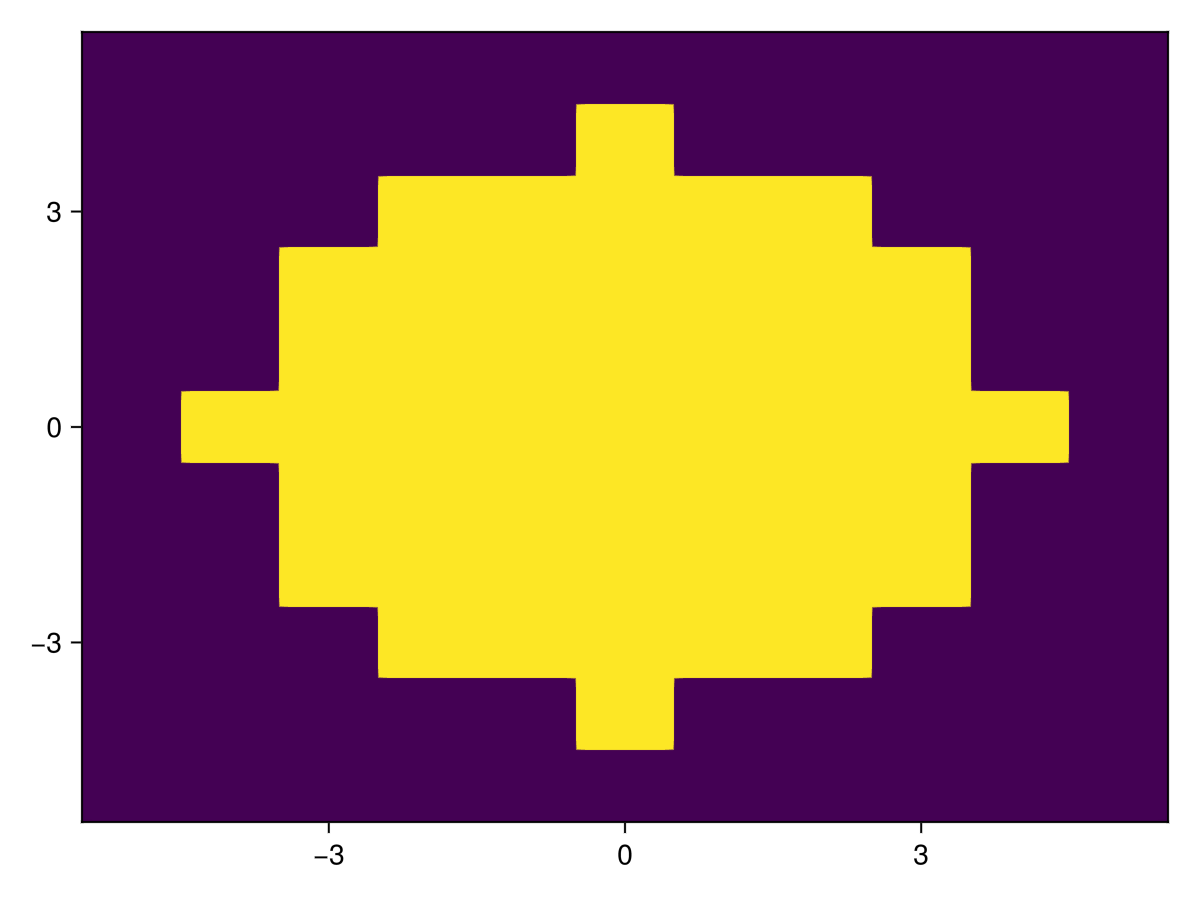

In [16]:
heatmap([[x...] for x in axes(dgtst)]...,dgtst)

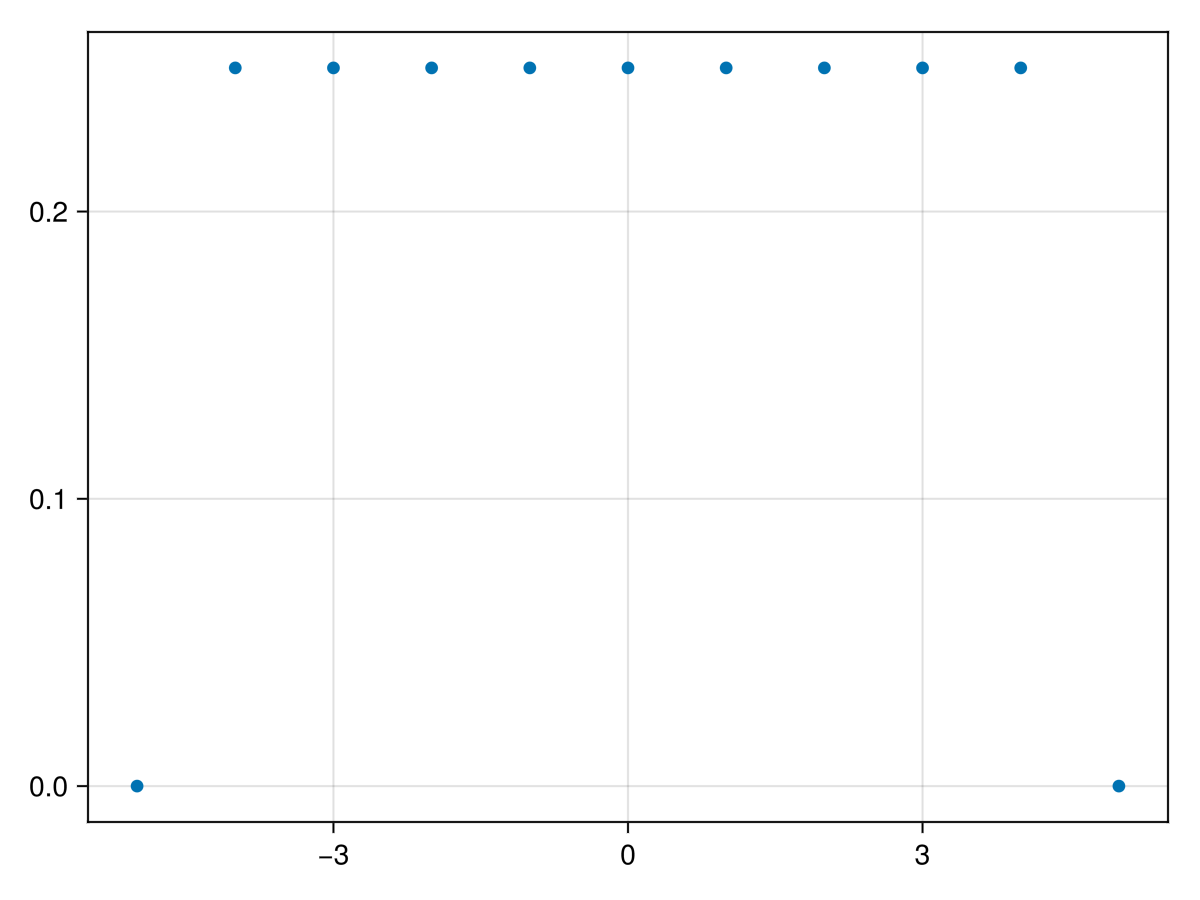

In [17]:
scatter(dgtst[0,:])

Our equations of motion come from
$$S=\int dt\, \langle \psi |i\partial_t|\psi\rangle - \langle \psi|H|\psi\rangle-\sum_j \lambda_j \sum_n |f_{jn}|^2 - \mu\sum_{jn} n |f_{jn}|^2$$
Where $\lambda_j$ and $\mu$ are Lagrange multipliers.  For each site we have a local constraint

$$\sum_n |f_{jn}|^2=1$$

One consequence is that we can make an arbitrary gauge transformation on each site

$$f_{jn}\to e^{i \theta_j} f_{j n}$$

The Lagrange Multiplier $\mu$ corresponds to number conservation

$$\sum_{jn} n |f_{jn}|^2=N$$

This gives us a global Gauge 

$$f_{jn}\to e^{i\theta n} f_{jn}$$

For small deviations, the projector onto the physical space takes the form

$$f_{jn}\to [\alpha_j + \beta (n-\bar n)]f_{jn}$$

In [18]:
#rotate f so that the average occupation is given by targn
@doc raw"""
    nproj!(f,targn)
    nproj!(f,targn;nbar=nbar)

Projects $f$ into the physical space, where $\sum_n |f_{jn}|^2=1$
and the averag number of particles per site is `targn`.

If `nbar` is specified, then it also does a gauge transformation
so that the coefficient of $f_{j\bar n}$ is real, and
so that the order parameter is real on the central site.
"""
function nproj!(f,targn;threshold=1e-12,nbar=nothing)
    nvals = nv(f)
    xvals = xv(f)
    A = 0.0
    B = 0.0
    C = 0.0

    for x in xvals
        F0 = 0.0
        F1 = 0.0
        F2 = 0.0
        F3 = 0.0
        for n in nvals
            p = abs2(f[x,n])
            dn = n - targn
            F0 += p
            F1 += dn * p
            F2 += dn * dn * p
            F3 += dn * dn * dn * p
        end
        invF0 = inv(F0)
        A += F1 * invF0
        B += (F1 * F1 * invF0 - F2) / sqrt(F0)
        C += F3 - 3 * F2 * F1 * invF0 + 2 * F1 * F1 * F1 * invF0 * invF0
    end

    beta = 0.0
    if abs(B) > threshold
        beta = A / (2 * B) + (A * A * C) / ((2 * B)^3)
    end

    for x in xvals
        alpha = 1.0
        if abs(beta) > threshold
            F0 = 0.0
            F1 = 0.0
            F2 = 0.0
            for n in nvals
                p = abs2(f[x,n])
                dn = n - targn
                F0 += p
                F1 += dn * p
                F2 += dn * dn * p
            end
            discriminant = beta^2 * F1^2 + (1 - beta^2 * F2) * F0
            if discriminant < 0
                continue
            end
            alpha = (-beta * F1 + sqrt(discriminant)) / F0
        end

        normsq = 0.0
        for n in nvals
            c = alpha + beta * (n - targn)
            f[x,n] *= c
            normsq += abs2(f[x,n])
        end

        phasefactor = sqrt(normsq)
        if !(nbar isa Nothing)
            f1 = f[x,nbar]
            if abs(f1) > threshold
                phasefactor *= f1 / abs(f1)
            end
        end
        invphase = inv(phasefactor)
        for n in nvals
            f[x,n] *= invphase
        end
    end

    if !(nbar isa Nothing)
        setphase!(f,nbar)
    end
    return f
end

function Nproj!(f,targN;threshold=1e-12,nbar=nothing)
    numsites=length(xv(f))
    nproj!(f,targN/numsites;threshold,nbar)
end
    

Nproj! (generic function with 1 method)

In [19]:
length(xv(gtst))

121

In [20]:
Nproj!(gtst,10)
density(gtst)

11×11 OffsetArray(::Matrix{Float64}, -5:5, -5:5) with eltype Float64 with indices -5:5×-5:5:
 0.0  0.0       0.0       0.0       …  0.0       0.0       0.0       0.0
 0.0  0.0       0.0       0.0          0.0       0.0       0.0       0.0
 0.0  0.0       0.0       0.217335     0.217335  0.0       0.0       0.0
 0.0  0.0       0.217335  0.217335     0.217335  0.217335  0.0       0.0
 0.0  0.0       0.217335  0.217335     0.217335  0.217335  0.0       0.0
 0.0  0.217335  0.217335  0.217335  …  0.217335  0.217335  0.217335  0.0
 0.0  0.0       0.217335  0.217335     0.217335  0.217335  0.0       0.0
 0.0  0.0       0.217335  0.217335     0.217335  0.217335  0.0       0.0
 0.0  0.0       0.0       0.217335     0.217335  0.0       0.0       0.0
 0.0  0.0       0.0       0.0          0.0       0.0       0.0       0.0
 0.0  0.0       0.0       0.0       …  0.0       0.0       0.0       0.0

In [21]:
sum(density(gtst))

10.649408126293679

The equations of motion are
\begin{align}
i e^{i\chi}\partial_t f_{jn}&= 
-\sum_i g_{ij} \left[ \psi_i^* \sqrt{n+1} f_{j,n+1} +\psi_i \sqrt{n} f_{j,n-1}\right]+ 
(\eta\, n(n-1)/2+\delta_j n) f_{jn}
\end{align}

In [22]:
# This is actually i df/dt, the way that I wrote it
# function dfdt(f,p,t)
#     g=p.g(t) #list of g's
#     eta=p.eta(t) #list of eta's
#     delta = p.delta(t) # list of deltas
#     sym=p.sym(t)
#     _dfdt(f,g,delta,eta,sym) # function barrier
# end
function dfdt(f,p,t)
    g=p.g(t) #scalar g
    eta=p.eta(t) #scalar eta
    delta = p.delta(t) # list of deltas
    result=similar(f)
    _dfdt!(result,f,g,delta,eta) # function barrier
end

function dfdt!(result,f,p,t)
    g=p.g(t) #scalar g
    eta=p.eta(t) #scalar eta
    delta = p.delta(t) # list of deltas
    #@show g eta typeof(delta)
    _dfdt!(result,f,g,delta,eta) # function barrier
end

function _dfdt!(result,f,g,delta,eta)
    ψ=psi(f)
    ax=axes(ψ,1)
    ay=axes(ψ,2)
    xmin=ax[begin]
    xmax=ax[end]
    ymin=ay[begin]
    ymax=ay[end]
    nvals=nv(f)
    rnvals=Iterators.drop(nvals,1)
    for x in xmin:xmax,n in nvals
        result[x,ymin,n]=0.
        result[x,ymax,n]=0.
    end
    for y in ymin:ymax, n in nvals
        result[xmin,y,n]=0.
        result[xmax,y,n]=0.
    end
    for x in xmin+1:xmax-1, y in ymin+1:ymax-1
        gpsi=g*ψ[x-1,y]
        gpsi+=g*ψ[x+1,y]
        gpsi+=g*ψ[x,y-1]
        gpsi+=g*ψ[x,y+1]
        for n in nvals
            result[x,y,n]=f[x,y,n]*(eta*n*(n-1)/2+delta[x,y]*n)
        end
        for n in rnvals
            result[x,y,n]-= gpsi*sqrt(n)*f[x,y,n-1]
            result[x,y,n-1]-= conj(gpsi)*sqrt(n)*f[x,y,n]
        end
    end
    return result
end 

_dfdt! (generic function with 1 method)

In [23]:
zV=[0. for x in xv(gtst)]

11×11 OffsetArray(::Matrix{Float64}, -5:5, -5:5) with eltype Float64 with indices -5:5×-5:5:
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0
 0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0

In [24]:
der1=dfdt(gtst,(g=t->1.,eta=t->1.,delta=t->(zV.+0.1)),0.)
der1.data[:,:,1]

11×11 OffsetArray(::Matrix{ComplexF64}, -5:5, -5:5) with eltype ComplexF64 with indices -5:5×-5:5:
 0.0+0.0im        0.0+0.0im        0.0+0.0im  …        0.0+0.0im  0.0+0.0im
 0.0+0.0im        0.0-0.0im        0.0-0.0im           0.0-0.0im  0.0+0.0im
 0.0+0.0im        0.0-0.0im  -0.824865-0.0im           0.0-0.0im  0.0+0.0im
 0.0+0.0im  -0.412432-0.0im  -0.683125+0.0im     -0.412432-0.0im  0.0+0.0im
 0.0+0.0im  -0.824865-0.0im     -1.048+0.0im     -0.824865-0.0im  0.0+0.0im
 0.0+0.0im  -0.318253+0.0im   -1.41287+0.0im  …  -0.318253+0.0im  0.0+0.0im
 0.0+0.0im  -0.824865-0.0im     -1.048+0.0im     -0.824865-0.0im  0.0+0.0im
 0.0+0.0im  -0.412432-0.0im  -0.683125+0.0im     -0.412432-0.0im  0.0+0.0im
 0.0+0.0im        0.0-0.0im  -0.824865-0.0im           0.0-0.0im  0.0+0.0im
 0.0+0.0im        0.0-0.0im        0.0-0.0im           0.0-0.0im  0.0+0.0im
 0.0+0.0im        0.0+0.0im        0.0+0.0im  …        0.0+0.0im  0.0+0.0im

In [25]:
function rk4step(x,p,dxdt,t,deltat;prefactor=1.0)
    k1=dxdt(x,p,t)
    k2=dxdt(x+prefactor*k1*(deltat/2),p,t+deltat/2)
    k3=dxdt(x+prefactor*k2*(deltat/2),p,t+deltat/2)
    k4=dxdt(x+prefactor*k3*deltat,p,t+deltat)
    return prefactor * (k1+2*k2+2*k3+k4)*(deltat/6)
end

rk4step (generic function with 1 method)

In [26]:
function rk4step!(x,p,dxdt!,t,deltat;result,k1,k2,k3,k4,prefactor=1.,temp)
    dxdt!(k1,x,p,t)
    temp .= x .+ (prefactor*deltat/2).*k1
    dxdt!(k2,temp,p,t+deltat/2)
    temp .= x .+ (prefactor*deltat/2).*k2
    dxdt!(k3,temp,p,t+deltat/2)
    temp .= x .+ (prefactor*deltat).*k3
    dxdt!(k4,temp,p,t+deltat)
    result .= (k1 .+ 2 .*k2 .+ 2 .*k3 .+k4).*(prefactor*deltat/6)
end

rk4step! (generic function with 1 method)

In [27]:
function gstep(f,p,dfdt,t,dt,targN,nbar)
    f=f+rk4step(f,p,dfdt,t,dt)
    Nproj!(f,targN;threshold=1e-12)
    return f
end

gstep (generic function with 1 method)

In [28]:
mutable struct OscillatingScalar{T}
    base :: T
    amp :: T
    ω :: Float64
end

(f :: OscillatingScalar)(t) = f.base+f.amp*cos(f.ω*t)

In [29]:
# function relaxstep!(f :: Gutz2D,N,R,V,g,eta,dt)
#     df=rk4step(f,(g=CScalar(g),eta=CScalar(eta),
#             delta=CBilliard(R,V)),dfdt,0.,dt;prefactor=-1.)
#     f .+=df
#     Nproj!(f,N)
#     return f
# end

function relaxstep!(f :: Gutz2D,p,N,dt,df,k1,k2,k3,k4,f2)
    rk4step!(f,p,dfdt!,0.,dt;result=df,k1,k2,k3,k4,temp=f2,prefactor=-1.)
    f .+=df
    Nproj!(f,N)
    return f
end

relaxstep! (generic function with 1 method)

In [30]:
# function expandstep!(f ::Gutz2D,g,η,ω,dg,dη,t,dt)
#     df=rk4step(f,(g=OscillatingScalar(g,dg,ω),eta=OscillatingScalar(η,dη,ω),
#             delta=CAScalar(0.)),dfdt,t,dt;prefactor=-1.0im)
#     f .+= df
#     standardize!(f,0)
#     return f
# end

# function expandstep!(f ::Gutz2D,N,g,η,ω,dg,dη,t,dt,df,k1,k2,k3,k4)
#     rk4step!(f,(g=CScalar(g),eta=CScalar(η),
#             delta=CBilliard(100.,10)),dfdt!,t,(-1.0im)*dt;result=df,k1,k2,k3,k4)
#     f .+=  df
#     standardize!(f,0)
#     Nproj!(f,N)
#     return f
# end

function expandstep!(f ::Gutz2D,p,N,t,dt,df,k1,k2,k3,k4,f2)
     rk4step!(f,p,dfdt!,t,dt;result=df,k1,k2,k3,k4,prefactor=-1.0im,temp=f2)
     f .+=  df
     standardize!(f,0)
     Nproj!(f,N)
     return f
end

expandstep! (generic function with 1 method)

In [31]:
function reshape(f :: Gutz2D,lx::Int,ly::Int;default=nothing)
    mN=maxN(f)
    oldminLx=Lxmin(f)
    oldmaxLx=Lx(f)
    oldminLy=Lymin(f)
    oldmaxLy=Ly(f)
    newdata=OffsetArray(zeros(ComplexF64,2lx+1,2ly+1,mN+1),(-lx-1,-ly-1,-1))
    for x in -lx:lx, y in -ly:ly
        if oldminLx<=x<=oldmaxLx && oldminLy<=y<=oldmaxLy
            newdata[x,y,:]=f[x,y,:]
        elseif !(default isa Nothing)
            newdata[x,y,:]=default
        end
    end
    return Gutz2D(newdata)
end

function reshape!(f :: Gutz2D,lx::Int,ly::Int;default=nothing)
    g=reshape(f,lx,ly;default)
    f.data=g.data
    return f
end

reshape! (generic function with 1 method)

In [32]:
mutable struct CBilliard{T}
    R ::Float64
    V ::T
end

Base.getindex(U::CBilliard,x,y)= x^2+y^2<=U.R^2 ? zero(U.V) : U.V

# Make it so that if you evaluate at time t
# it just returns the same object
(U::CBilliard)(t)=U

mutable struct CSquareBilliard{T}
    R ::Float64
    V ::T
end

Base.getindex(U::CSquareBilliard,x,y)= x^2<=U.R^2 && y^2<=U.R^2 ? zero(U.V) : U.V

# Make it so that if you evaluate at time t
# it just returns the same object
(U::CSquareBilliard)(t)=U

mutable struct CScalar{T}
    V ::T
end

(U::CScalar)(t)=U.V

Base.getindex(U::CScalar,ind...)=U.V

mutable struct CAScalar{T}
    V ::T
end 

(U::CAScalar)(t)=U
Base.getindex(U::CAScalar,ind...)=U.V


In [33]:
mutable struct CHarmonic
    R ::Float64
end

Base.getindex(U::CHarmonic,x,y)=(x^2+y^2)/(2*U.R^2)

(U::CHarmonic)(t)=U

In [34]:
function validate_float(str)
    val = tryparse(Float64, str)
    if isnothing(val)
        return false
    else
        return true
    end
end

function validate_int(str)
    val = tryparse(Int, str)
    if isnothing(val)
        return false
    else
        return true
    end
end

function validate_posfloat(str)
    val = tryparse(Float64, str)
    if isnothing(val) || val<=0
        return false
    else
        return true
    end
end

validate_posfloat (generic function with 1 method)

Now lets make a gui for playing with this:
Entry boxes for setting:
eta, deltag, deltaeta, oscillation frequency
Number of lattice sites, Number of particles
Slider for:
Radius of initial box trap
RK4 Timestep
Display time
Button for:
Reset to uniform disk
Relax
Expand
Pause
Show:
2D Density
Slice: 
Density
density contribution from each number
order parameter

In [35]:
function reset!(f:: Gutz2D,R,u0,v0=nothing)
    setdisk!(f,R,u0,v0)
    normalize!(f)
end
        

reset! (generic function with 2 methods)

In [36]:
function expansionviz(;mN=5)
    # Make Figure
    fig=Figure()
    display(fig)
    ax_main=Axis(fig[1,1][1,1])
    ax_slice=Axis(fig[1,1][2,1])
    controlpanel=fig[1,2][1,1]
    sliderpanel=fig[1,2][2,1]
    buttonpanel=fig[1,2][3,1]
    # Entry boxes
    Label(controlpanel[1,2],text="Main")
    Label(controlpanel[2,1],text="g=")
    Label(controlpanel[2,2],text="1")
    Label(controlpanel[2,1],text="η=")
    etabox=Textbox(controlpanel[3,2],reset_on_defocus=true,
        validator=validate_float,width=200,stored_string="1")
    η=@lift tryparse(Float64,$(etabox.stored_string))
    #Label(controlpanel[4,1],text="N=")
    #Nbox=Textbox(controlpanel[4,2],reset_on_defocus=true,
    #    validator=validate_float,width=200,stored_string="100")
    #N=@lift tryparse(Float64,$(Nbox.stored_string))
    Label(controlpanel[4,1],text="u0=")
    uboxes=Textbox[]
    for j in 0:mN
        box=Textbox(controlpanel[4,2][1,j+1],
        reset_on_defocus=true,
        validator=validate_float,width=60,stored_string=
        j==1 ? "1" : "0")
        push!(uboxes,box)
    end
    ustrings = [u.stored_string for u in uboxes]
    u0 = lift((args...) -> [tryparse(Float64,u) for u in args], ustrings...)
    #u0 = @lift map(u -> tryparse(Float64, $(u.stored_string)), uboxes)
    #u0=@lift([tryparse(Float64,$u.stored_string) for u in uboxes])
    Label(controlpanel[5,1],text="L=")
    Lbox=Textbox(controlpanel[5,2],reset_on_defocus=true,
        validator=validate_int,width=200,stored_string="10")
    L=@lift tryparse(Int,$(Lbox.stored_string))
    N=Observable(0.)
    Nstring = lift(s->"$s",N)
    Label(controlpanel[6,1],text="N=")
    Nbox=Label(controlpanel[6,2],text=Nstring)
    Label(controlpanel[7,1],text="V=")
    Vbox=Textbox(controlpanel[7,2],reset_on_defocus=true,
        validator=validate_float,width=200,stored_string="10")
    Label(controlpanel[8,1],text="ω=")
    omegabox=Textbox(controlpanel[8,2],reset_on_defocus=true,
        validator=validate_float,width=200,stored_string="1")
    ω=@lift tryparse(Float64,$(omegabox.stored_string))
    Label(controlpanel[9,1],text="δg=")
    dgbox=Textbox(controlpanel[9,2],reset_on_defocus=true,
        validator=validate_float,width=200,stored_string="0")
    dg=@lift tryparse(Float64,$(dgbox.stored_string))
    Label(controlpanel[10,1],text="δη=")
    detabox=Textbox(controlpanel[10,2],reset_on_defocus=true,
        validator=validate_float,width=200,stored_string="0")
    dη=@lift tryparse(Float64,$(detabox.stored_string))
    Label(controlpanel[11,2],text="Simulation")
    Label(controlpanel[12,1],text="timestep=")
    dtbox=Textbox(controlpanel[12,2],reset_on_defocus=true,
        validator=validate_posfloat,width=200,stored_string="0.01")
    dt=@lift tryparse(Float64,$(dtbox.stored_string))
    Label(controlpanel[13,1],text="display timestep=")
    displaytbox=Textbox(controlpanel[13,2],reset_on_defocus=true,
        validator=validate_posfloat,width=200,stored_string="0.01")
    displayt=@lift tryparse(Float64,$(displaytbox.stored_string))
    T=Observable("0.")
    Label(controlpanel[14,1],text="t=")
    tbox=Label(controlpanel[14,2],text=T)
    V=@lift tryparse(Float64,$(Vbox.stored_string))
    #
    # Sliders
    # Set it up as a slider grid, so we can add more sliders later
    sliders=SliderGrid(sliderpanel[2,1],
        (label="R",range=1:L[],startvalue=L[],format="{:d}"))
    Rslider=sliders.sliders[1]
    R=Rslider.value
    on(L) do L
        Rslider.range=1:2*L
    end
    #
    # Buttons
    reset_button=Button(buttonpanel[1,1];label="reset",tellwidth=false)
    relax_button=Button(buttonpanel[2,1][1,1];label="circle",tellwidth=false)
    square_button=Button(buttonpanel[2,1][1,2];label="square",tellwidth=false)
    harmonic_button=Button(buttonpanel[2,1][1,3];label="harmonic",tellwidth=false)
    expand_button=Button(buttonpanel[3,1];label="expand",tellwidth=false)
    pause_button=Button(buttonpanel[4,1];label="pause",tellwidth=false)
    # Setup
    f=Observable(Gutz2D(L[],L[],mN))
    v0=zeros(nv(f[]))
    v0[0]=1.
    df=Gutz2D(L[],L[],mN)
    k1=Gutz2D(L[],L[],mN)
    k2=Gutz2D(L[],L[],mN)
    k3=Gutz2D(L[],L[],mN)
    k4=Gutz2D(L[],L[],mN)
    f2=Gutz2D(L[],L[],mN)
    relaxp=@lift (g=CScalar(1.),eta=CScalar($η),delta=CBilliard(Float64($R),$V))
    squarep=@lift (g=CScalar(1.),eta=CScalar($η),delta=CSquareBilliard(Float64($R),$V))
    expandp=@lift (g=OscillatingScalar(1.,$dg,$ω),eta=OscillatingScalar($η,$dη,$ω),
                    delta=CAScalar(0.))
    harmonicp=@lift (g=CScalar(1.),eta=CScalar($η),delta=CHarmonic(Float64($R)))
    isrunning_notifier = Condition()
    isrunning=Observable(false)
    relax=Ref(true)
    harmonic=Ref(false)
    square=Ref(false)
    # Figures
    #ρ=@lift density($f)
    # Alternatively could make a custom observable
    # that checks the size of ρ:  If it matches `f`
    # then we use `density!` and do an in-place replace
    # otherwise call `density`.  That will save a
    # lot of heap allocations, and speed hings up
    # signficantly
    # Here is my version -- will need debugging
    ρ=Observable(density(f[]))
    ρparent = @lift ($ρ).parent
    on(f) do f
        #println("f has been updated")
        #@show size(f) size(ρ[])
        if size(f)[1:2]==size(ρ[])
            #println("update ρ in place")
            density!(ρ[],f)
            notify(ρ)
        else
            #println("replace ρ")
            ρ[]=density(f)
        end
    end
    xvals= @lift [axes($ρ,1)...]
    yvals= @lift [axes($ρ,2)...]
    heatmap!(ax_main,xvals,yvals,ρparent)
    ρslice=@lift $ρ[0,:]
    scatter!(ax_slice,ρslice)
    # Textbox hooks
    on(L) do L
        reshape!(f[],L[],L[];default=v0)
        normalize!(f[])
        reshape!(df,L[],L[])
        reshape!(k1,L[],L[])
        reshape!(k2,L[],L[])
        reshape!(k3,L[],L[])
        reshape!(k4,L[],L[])
        reshape!(f2,L[],L[])
        notify(f)
    end
    # Slider Hooks
    # Button Hooks
    t=Ref(0.)
    on(ρ) do ρ
        autolimits!(ax_slice)
        autolimits!(ax_main)
    end    
    on(reset_button.clicks) do clicks
        reset!(f[],R[],u0[],v0)
        notify(f)
        N[]=sum(ρ[])
        T[]=string(0.)
    end
    on(relax_button.clicks) do clicks
        relax[]=true
        harmonic[]=false
        square[]=false
        isrunning[]=true
    end
    on(square_button.clicks) do clicks
        relax[]=false
        harmonic[]=false
        square[]=true
        isrunning[]=true
    end
    on(expand_button.clicks) do clicks
        relax[]=false
        harmonic[]=false
        square[]=false
        isrunning[]=true
    end
    on(harmonic_button.clicks) do clicks
        relax[]=false
        harmonic[]=true
        square[]=false
        isrunning[]=true
    end
    on(pause_button.clicks) do clicks
        isrunning[]=false
    end
    # Main Loop
    lastdisplay=Ref(0.)
    on(cond -> cond && notify(isrunning_notifier), isrunning)
    errormonitor(
        @async while true
            if isrunning[]
                isopen(fig.scene) || break # stops if window is closed
                if relax[]
                    relaxstep!(f[],relaxp[],N[],dt[],df,k1,k2,k3,k4,f2)
                elseif square[]
                    relaxstep!(f[],squarep[],N[],dt[],df,k1,k2,k3,k4,f2)
                elseif harmonic[]
                    relaxstep!(f[],harmonicp[],N[],dt[],df,k1,k2,k3,k4,f2)
                else
                    expandstep!(f[],expandp[],N[],t[],dt[],df,k1,k2,k3,k4,f2)
                end
                lastdisplay[]+=dt[]
                t[]+=dt[]
                if lastdisplay[]>displayt[]
                    notify(f)
                    lastdisplay[]=0.
                    T[]=string(round(t[],digits=3))
                    #isrunning[]=false
                end
                # Let Makie process UI/render events between simulation steps.
                yield()
            else
                wait(isrunning_notifier)
            end
        end)
end

expansionviz (generic function with 1 method)

In [37]:
struct timeseries{T}
    times :: Vector{Float64}
    data :: Vector{T}
end

In [42]:
function Num(f::Gutz2D)
    N=0.
    nvals = nv(f) 
    xvals= xv(f)
    for x in xvals
        num=0.
        den=0.
        for n in nvals
            f2=abs2(f[x,n])
            num += n*f2
            den += f2
        end
        N+= num/den
    end
    return N
end

Num (generic function with 1 method)

In [50]:
function squaredifference(f1::Gutz2D,f2::Gutz2D)
    dif=0.
    for xn in eachindex(f1)
        dif+=abs2(f1[xn]-f2[xn])
    end
    return dif
end

squaredifference (generic function with 1 method)

In [67]:
function energy(f,p,t)
    g=p.g(t) #scalar g
    eta=p.eta(t) #scalar eta
    delta = p.delta(t) 
    _energy(f,g,delta,eta)
end

function _energy(f,g,delta,eta)
    ψ=psi(f)
    ax=axes(ψ,1)
    ay=axes(ψ,2)
    xmin=ax[begin]
    xmax=ax[end]
    ymin=ay[begin]
    ymax=ay[end]
    nvals=nv(f)
    rnvals=Iterators.drop(nvals,1)
    energy=0.
    for x in xmin+1:xmax-1, y in ymin+1:ymax-1
        energy-= 2*g*real(ψ[x,y]*conj(ψ[x+1,y]+ψ[x,y+1]))
        for n in rnvals
            energy += n*delta[x,y]*abs2(f[x,y,n])
            energy += (n*(n-1)/2)*eta*abs2(f[x,y,n])
        end
    end
    return energy
end

_energy (generic function with 1 method)

In [68]:
density(gtst)

11×11 OffsetArray(::Matrix{Float64}, -5:5, -5:5) with eltype Float64 with indices -5:5×-5:5:
 0.0  0.0       0.0       0.0       …  0.0       0.0       0.0       0.0
 0.0  0.0       0.0       0.0          0.0       0.0       0.0       0.0
 0.0  0.0       0.0       0.217335     0.217335  0.0       0.0       0.0
 0.0  0.0       0.217335  0.217335     0.217335  0.217335  0.0       0.0
 0.0  0.0       0.217335  0.217335     0.217335  0.217335  0.0       0.0
 0.0  0.217335  0.217335  0.217335  …  0.217335  0.217335  0.217335  0.0
 0.0  0.0       0.217335  0.217335     0.217335  0.217335  0.0       0.0
 0.0  0.0       0.217335  0.217335     0.217335  0.217335  0.0       0.0
 0.0  0.0       0.0       0.217335     0.217335  0.0       0.0       0.0
 0.0  0.0       0.0       0.0          0.0       0.0       0.0       0.0
 0.0  0.0       0.0       0.0       …  0.0       0.0       0.0       0.0

In [71]:
@time energy(gtst,(g=CScalar(0.),eta=CScalar(0),delta=CBilliard(0.,1.)),0.)

  0.000009 seconds (7 allocations: 2.141 KiB)


10.432073266573408

In [52]:
squaredifference(gtst,1.01*gtst)

0.01209999999999997

In [74]:
htst=copy(gtst)

G2D(x=-5:5,y=-5:5;maxN=2)

In [75]:
gtst[1,1,0]=10.

10.0

In [76]:
htst[1,1,0]

0.8846836385283278 + 0.0im

In [78]:
similar(gtst)

G2D(x=-5:5,y=-5:5;maxN=2)

In [77]:
@time Num(gtst)

  0.000010 seconds


10.434241901969914

In [48]:
@time sum(density(gtst))

  0.000014 seconds (4 allocations: 1.078 KiB)


10.649408126293679

In [72]:
nothing isa Nothing

true

In [ ]:
function initialize(L,R,mN,u0)
    f=Gutz2D(L,L,mN)
    v0=zeros(nv(f))
    v0[0]=1.
    reset!(f,R,u0,v0)
    return f
end

"""
typical values for `delta`

- `delta=CBilliard(R,V)` -- trap of height V and radius R
- `delta=CSquareBilliard(R,V)` -- square trap of height V and radius R (so diameter 2R)
- `delta=CHarmonic(R)` -- harmonic trap
"""
function relax!(f::Gutz2D;g=1.,η,delta,dt,maxiterations=1000,threshold=1e-6,
        storeE::Bool=false,storef::Bool=false,storeinterval::Int=1)
    p=(g=CScalar(Float64(g)),eta=CScalar(Float64(η)),delta=delta)
    N=Num(f)
    df=similar(f)
    k1=similar(f)
    k2=similar(f)
    k3=similar(f)
    k4=similar(f)
    f2=similar(f)
    oldE=energy(f,p,0.)
    E=oldE
    Elist= storeE ?  timeseries([0.],[E]) : nothing 
    flist= storef ? timeseries([0.],[copy(f)]) : nothing 
    numit=0
    sit=0
    for j in 1:maxiterations
        numit=j
        sit+=1
        relaxstep!(f,p,N,dt,df,k1,k2,k3,k4,f2)
        E=energy(f,p,0.)
        if E-oldE<threshold
            break
        end
        oldE=E
        if storeE  && sit >=storeinterval
            push!(Elist.times,j*dt)
            push!(Elist.data,E)
            sit=0
        end
        if storef && sit >=storeinterval
            push!(flist.times,j*dt)
            push!(flist.data,copy(f))
            sit=0
        end
    end
    return (f=f,numit=numit,Elist=Elist,flist=flist)
end

function evolve!(f;dg,ω,dη,η,delta=CAScalar(0.),dt,iterations,
        storef::Bool=false,storeinterval::Int=1)
    p=(g=OscillatingScalar(1.,dg,ω),eta=OscillatingScalar(η,dη,ω),
                    delta=delta)
    N=Num(f)
    df=similar(f)
    k1=similar(f)
    k2=similar(f)
    k3=similar(f)
    k4=similar(f)
    f2=similar(f)
    sit=0
    flist= (storef !== nothing) ? nothing : timeseries([0.],[copy(f)])
    for j in 1:interations
        t=j*dt
        sit+=1
        expandstep!(f,p,N,t,dt,df,k1,k2,k3,k4,f2)
        if storef && sit >=storeinterval
            push!(flist.times,j*dt)
            push!(flist.data,copy(f))
            sit=0
        end
    end
    return (f=f,flist=flist)
end

evolve! (generic function with 1 method)